# Tongue Twister: Exploring Oral Cancer Image Classification

**Research question:** How do two pretrained convolutional networks (ResNet18 and ResNet50) compare when classifying a small public oral-image dataset?

This is an educational computer-vision experiment, **not a diagnostic tool**. Images are not MRI scans. Dataset performance cannot establish clinical reliability.

**Previous baseline:** An earlier exploratory notebook used ResNet50 and reported 92.59% validation accuracy on 27 images. That result used random augmentations in validation and had no independent test set, so it is **not directly comparable** to the new experiment.

**Changes in this version:** reproducible stratified train/validation/test split; deterministic evaluation transforms; two model comparison; training curves; confusion matrices and error inspection. Because patient identifiers are unavailable, image-level splits may leak related images across partitions. Treat all results as exploratory.

## 1. Setup
Run in Google Colab with a GPU if available. Install missing packages using the optional cell.

In [1]:
# %pip install -q kagglehub torch torchvision scikit-learn pandas matplotlib pillow

In [2]:
import os, random, copy, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, accuracy_score, balanced_accuracy_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


## 2. Download and inspect the data
The class names come from the dataset folders. Confirm that the folder names and images match the intended task before interpreting any model output.

In [3]:
root = Path(kagglehub.dataset_download('shivam17299/oral-cancer-lips-and-tongue-images'))
folders = [p for p in root.rglob('*') if p.is_dir() and {'cancer', 'non-cancer'}.issubset({c.name for c in p.iterdir() if c.is_dir()})]
if not folders: raise FileNotFoundError(f'Could not find cancer/non-cancer folders beneath {root}')
data_dir = folders[0]
raw = datasets.ImageFolder(str(data_dir))
class_names = raw.classes
print('Classes:', class_names, '| Total images:', len(raw))
print(pd.Series([class_names[y] for y in raw.targets]).value_counts())
assert len(class_names) == 2, 'This notebook assumes two classes.'
assert 'cancer' in class_names, 'Expected a cancer class.'

Classes: ['cancer', 'non-cancer'] | Total images: 131
cancer        87
non-cancer    44
Name: count, dtype: int64


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


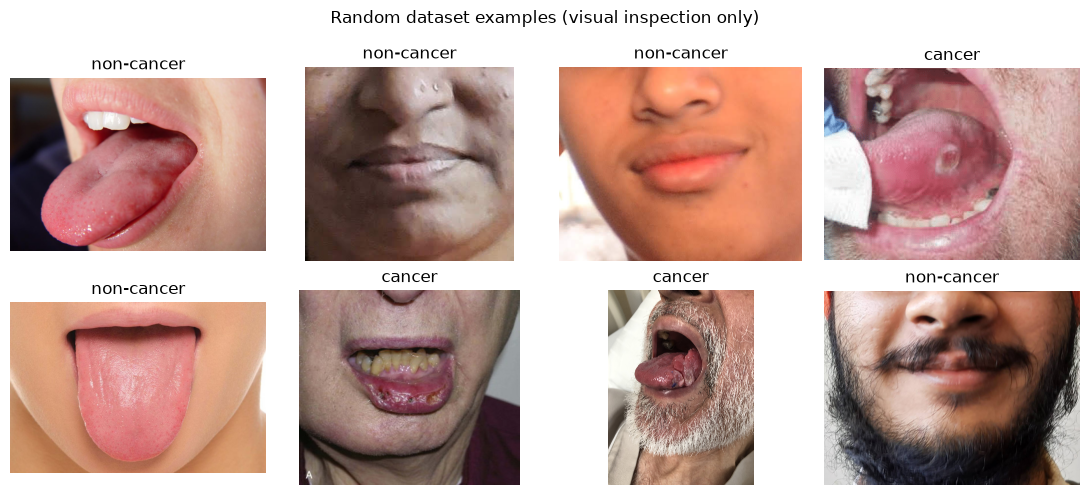

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for ax, idx in zip(axes.flat, np.random.default_rng(SEED).choice(len(raw), min(8,len(raw)), replace=False)):
    img, label = raw[int(idx)]
    ax.imshow(img.convert('RGB')); ax.set_title(class_names[label]); ax.axis('off')
for ax in axes.flat[len(raw):]: ax.axis('off')
plt.suptitle('Random dataset examples (visual inspection only)'); plt.tight_layout(); plt.show()

## 3. Reproducible split and preprocessing
Use a **70% training / 15% validation / 15% test** image-level split, stratified by label. No random augmentation is applied to validation or test images.

In [5]:
indices = np.arange(len(raw)); labels = np.array(raw.targets)
train_idx, hold_idx = train_test_split(indices, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(hold_idx, test_size=0.50, stratify=labels[hold_idx], random_state=SEED)
for name, idx in [('Train',train_idx),('Validation',val_idx),('Test',test_idx)]:
    print(name, len(idx), {class_names[k]:int(sum(labels[idx]==k)) for k in range(2)})
assert len(set(train_idx)&set(val_idx)) == len(set(train_idx)&set(test_idx)) == len(set(val_idx)&set(test_idx)) == 0

train_tf = transforms.Compose([transforms.Resize((224,224)), transforms.RandomHorizontalFlip(),
                               transforms.RandomRotation(15), transforms.ToTensor(),
                               transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
eval_tf = transforms.Compose([transforms.Resize((224,224)), transforms.ToTensor(),
                              transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
class IndexedImages(Dataset):
    def __init__(self, imagefolder, indices, transform):
        self.samples = [imagefolder.samples[int(i)] for i in indices]
        self.transform = transform
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        path, label = self.samples[i]
        with Image.open(path) as image: x = self.transform(image.convert('RGB'))
        return x, label

train_ds = IndexedImages(raw,train_idx,train_tf)
val_ds = IndexedImages(raw,val_idx,eval_tf)
test_ds = IndexedImages(raw,test_idx,eval_tf)
train_loader = DataLoader(train_ds,batch_size=16,shuffle=True,num_workers=0)
val_loader = DataLoader(val_ds,batch_size=16,shuffle=False,num_workers=0)
test_loader = DataLoader(test_ds,batch_size=16,shuffle=False,num_workers=0)

Train 91 {'cancer': 60, 'non-cancer': 31}
Validation 20 {'cancer': 13, 'non-cancer': 7}
Test 20 {'cancer': 14, 'non-cancer': 6}


## 4. Compare two pretrained models
Freeze each ImageNet feature extractor and train only a new two-class linear head. This keeps the comparison approachable and limits the number of trainable parameters. **Hypothesis to investigate:** the larger ResNet50 may not necessarily outperform ResNet18 on this small dataset.

In [6]:
def build_model(name):
    if name == 'resnet18':
        net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    elif name == 'resnet50':
        net = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    else: raise ValueError(name)
    for p in net.parameters(): p.requires_grad = False
    features = net.fc.in_features
    net.fc = nn.Sequential(nn.Dropout(0.3),nn.Linear(features,len(class_names)))
    return net.to(device)

def one_epoch(model,loader,criterion,optimizer=None):
    training = optimizer is not None
    model.train(training)
    # Frozen feature extractors retain eval-mode batch-normalization statistics.
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm): module.eval()
    loss_sum, correct, count = 0.,0,0
    for x,y in loader:
        x,y=x.to(device),y.to(device)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits=model(x); loss=criterion(logits,y)
            if training: loss.backward(); optimizer.step()
        loss_sum += loss.item()*len(y)
        correct += (logits.argmax(1)==y).sum().item(); count += len(y)
    return loss_sum/count, correct/count

def fit(name, epochs=10, lr=1e-3):
    model=build_model(name)
    opt=torch.optim.AdamW(model.fc.parameters(),lr=lr)
    criterion=nn.CrossEntropyLoss()
    history=[]; best_acc=-1.; best_state=None
    for epoch in range(epochs):
        tr_loss,tr_acc=one_epoch(model,train_loader,criterion,opt)
        va_loss,va_acc=one_epoch(model,val_loader,criterion)
        history.append({'epoch':epoch+1,'train_loss':tr_loss,'train_acc':tr_acc,
                        'val_loss':va_loss,'val_acc':va_acc})
        if va_acc>best_acc:
            best_acc=va_acc; best_state=copy.deepcopy(model.state_dict())
        print(f'{name} {epoch+1:02d}/{epochs} | train {tr_acc:.3f} | val {va_acc:.3f}')
    model.load_state_dict(best_state)
    return model,pd.DataFrame(history)

## 5. Run experiments
Training runs only when you execute this cell. Both models use the same split, epoch count, learning rate, optimizer, and augmentation policy. Small-sample results can vary considerably; consider repeating with multiple seeds later.

In [7]:
import os
import ssl
import certifi

# Tell Python which trusted certificates to use
os.environ["SSL_CERT_FILE"] = certifi.where()

# Check the certificate location
print("Certificate bundle:", certifi.where())
print("Python SSL paths:", ssl.get_default_verify_paths())

Certificate bundle: /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/certifi/cacert.pem
Python SSL paths: DefaultVerifyPaths(cafile='/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/certifi/cacert.pem', capath=None, openssl_cafile_env='SSL_CERT_FILE', openssl_cafile='/Library/Frameworks/Python.framework/Versions/3.14/etc/openssl/cert.pem', openssl_capath_env='SSL_CERT_DIR', openssl_capath='/Library/Frameworks/Python.framework/Versions/3.14/etc/openssl/certs')


In [8]:
EPOCHS = 10
trained = {}
histories = {}

for architecture in ["resnet18", "resnet50"]:
    trained[architecture], histories[architecture] = fit(
        architecture, epochs=EPOCHS
    )

    torch.save(
        {
            "model_name": architecture,
            "state_dict": trained[architecture].state_dict(),
            "classes": class_names,
            "seed": SEED
        },
        f"{architecture}_tongue_twister.pth"
    )

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/jinlu/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 23.4MB/s]


resnet18 01/10 | train 0.549 | val 0.650
resnet18 02/10 | train 0.648 | val 0.500
resnet18 03/10 | train 0.747 | val 0.550
resnet18 04/10 | train 0.725 | val 0.700
resnet18 05/10 | train 0.758 | val 0.700
resnet18 06/10 | train 0.824 | val 0.700
resnet18 07/10 | train 0.813 | val 0.750
resnet18 08/10 | train 0.835 | val 0.800
resnet18 09/10 | train 0.868 | val 0.750
resnet18 10/10 | train 0.846 | val 0.750
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /Users/jinlu/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:06<00:00, 15.7MB/s]


resnet50 01/10 | train 0.604 | val 0.650
resnet50 02/10 | train 0.736 | val 0.700
resnet50 03/10 | train 0.780 | val 0.800
resnet50 04/10 | train 0.802 | val 0.900
resnet50 05/10 | train 0.857 | val 0.900
resnet50 06/10 | train 0.857 | val 0.950
resnet50 07/10 | train 0.868 | val 0.950
resnet50 08/10 | train 0.868 | val 0.950
resnet50 09/10 | train 0.846 | val 0.950
resnet50 10/10 | train 0.890 | val 0.950


## 6. Compare validation results and learning curves
Select the model using **validation data only**. Do not use test scores to tune hyperparameters.

,model,best_validation_accuracy,final_train_accuracy,final_validation_loss
0,resnet18,0.80,0.846154,0.452847
1,resnet50,0.95,0.890110,0.335756


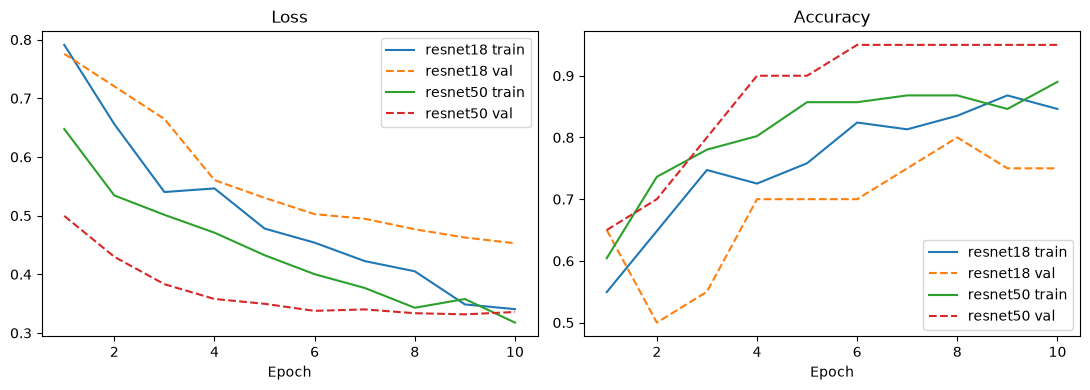

Selected using validation only: resnet50


In [9]:
summary=pd.DataFrame([{'model':name,'best_validation_accuracy':h.val_acc.max(),
                       'final_train_accuracy':h.train_acc.iloc[-1],
                       'final_validation_loss':h.val_loss.iloc[-1]} for name,h in histories.items()])
display(summary)
fig,axs=plt.subplots(1,2,figsize=(11,4))
for name,h in histories.items():
    axs[0].plot(h.epoch,h.train_loss,label=f'{name} train')
    axs[0].plot(h.epoch,h.val_loss,'--',label=f'{name} val')
    axs[1].plot(h.epoch,h.train_acc,label=f'{name} train')
    axs[1].plot(h.epoch,h.val_acc,'--',label=f'{name} val')
axs[0].set_title('Loss');axs[1].set_title('Accuracy')
for ax in axs:ax.set_xlabel('Epoch');ax.legend()
plt.tight_layout();plt.show()
selected=summary.sort_values(['best_validation_accuracy','final_validation_loss'],ascending=[False,True]).iloc[0]['model']
print('Selected using validation only:',selected)

## 7. One-time held-out test evaluation
With only about 20 test images, uncertainty is substantial. Report the sample counts and confusion matrix alongside accuracy. **Positive class = cancer**, even though alphabetical folder order assigns it index 0.

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Test images: 20 | Correct: 19
Accuracy: 0.95
Balanced accuracy: 0.917
              precision    recall  f1-score   support

      cancer       0.93      1.00      0.97        14
  non-cancer       1.00      0.83      0.91         6

    accuracy                           0.95        20
   macro avg       0.97      0.92      0.94        20
weighted avg       0.95      0.95      0.95        20

ROC-AUC (cancer positive): 0.94


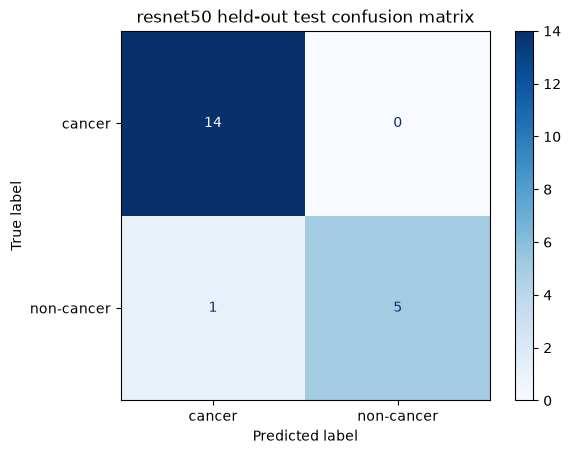

In [10]:
@torch.no_grad()
def predict(model,loader):
    model.eval(); y_true=[]; y_pred=[]; cancer_prob=[]
    cancer_index=class_names.index('cancer')
    for x,y in loader:
        logits=model(x.to(device))
        prob=torch.softmax(logits,dim=1).cpu().numpy()
        y_true.extend(y.numpy().tolist())
        y_pred.extend(prob.argmax(1).tolist())
        cancer_prob.extend(prob[:,cancer_index].tolist())
    return np.array(y_true),np.array(y_pred),np.array(cancer_prob)

true,pred,prob=predict(trained[selected],test_loader)
positive=class_names.index('cancer')
true_binary=(true==positive).astype(int)
print('Test images:',len(true),'| Correct:',int((true==pred).sum()))
print('Accuracy:',round(accuracy_score(true,pred),3))
print('Balanced accuracy:',round(balanced_accuracy_score(true,pred),3))
print(classification_report(true,pred,labels=list(range(len(class_names))),target_names=class_names,zero_division=0))
if len(np.unique(true_binary))==2:
    print('ROC-AUC (cancer positive):',round(roc_auc_score(true_binary,prob),3))
else: print('ROC-AUC unavailable: test set contains only one class')
ConfusionMatrixDisplay.from_predictions(true,pred,labels=list(range(len(class_names))),
                                        display_labels=class_names,cmap='Blues')
plt.title(f'{selected} held-out test confusion matrix');plt.show()

## 8. Inspect mistakes
Looking at misclassified images can reveal possible dataset issues, but visual inspection alone cannot establish why the model failed. Avoid presenting any predictions as medical judgments.

Misclassified test images: 1


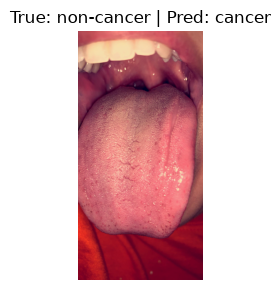

In [11]:
wrong=np.flatnonzero(true!=pred)
print('Misclassified test images:',len(wrong))
if len(wrong):
    fig,axes=plt.subplots(1,min(5,len(wrong)),figsize=(3*min(5,len(wrong)),3))
    axes=np.atleast_1d(axes)
    for ax,j in zip(axes,wrong[:5]):
        path,_=test_ds.samples[int(j)]
        with Image.open(path) as im:ax.imshow(im.convert('RGB'))
        ax.set_title(f'True: {class_names[true[j]]} | Pred: {class_names[pred[j]]}')
        ax.axis('off')
    plt.tight_layout();plt.show()
else: print('No mistakes in this small test set; this does not establish generalization.')

## 9. Research notes

**What I expected:** Given the small dataset of 131 images, I also thought ResNet18 might perform similarly or even better. Since both models use pretrained weights, a larger architecture might not necessarily provide a significant advantage for this classification task.

**What happened:** The selected model achieved 95% accuracy on the held-out test set, correctly classifying 19 out of 20 images. It also achieved a balanced accuracy of 91.7% and a ROC-AUC of 0.94.

One result I found interesting was the difference in recall between the two classes. The model correctly identified all 14 cancer images (100% recall), but only 5 of the 6 non-cancer images (83% recall). This means the model incorrectly classified one non-cancer image as cancerous.

Although the overall accuracy was high, the small test set makes it difficult to draw strong conclusions. With only 20 images, a single incorrect prediction changes the overall accuracy by 5 percentage points. This reinforced the importance of looking beyond accuracy and examining class-specific performance, particularly for medical applications where false positives and false negatives have different consequences.

The ResNet18 and ResNet50 validation comparison should also be considered when deciding whether the additional complexity of ResNet50 is justified.

**What I would change next:** One of the biggest limitations of this project is the dataset size. With so few images, even a handful of incorrect predictions can significantly affect the reported accuracy. I would like to investigate how performance changes across different random seeds and compare the results against a simpler baseline.

I would also explore patient-level data splitting to reduce potential data leakage, investigate duplicate images, and evaluate the models on an independent dataset. These improvements would help determine whether the models are learning meaningful visual patterns or simply performing well on a limited collection of images.

**Scope:** This project uses publicly available oral images rather than MRI scans. Although my original interest was in detecting tongue tumours using MRI, I chose to begin with a simpler image-classification problem to develop my understanding of PyTorch and transfer learning.

In the future, I hope to apply what I've learned to MRI-based tumour classification, where I can explore how different imaging modalities and preprocessing techniques affect model performance.